# Laboratorio 4B · Reconocimiento con modelos preentrenados

En el Laboratorio 4A, **MantenIA**, la empresa ficticia de mantenimiento industrial del curso, ajustó la estación que cuenta las cápsulas blandas de un cliente farmacéutico, también ficticio. Ahora el cliente pide más: **separar las cápsulas por defecto**. Unas tienen una burbuja de aire, otras salieron deformes y otras traen una mancha oscura.

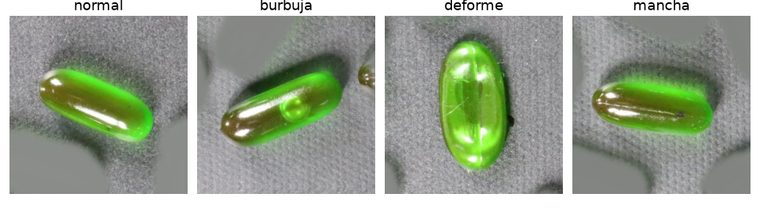

*Fotos: conjunto VisA (Zou et ál., 2022), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es), recortadas.*

Con el pipeline del 4A habría que diseñar una medida para cada defecto: el alargamiento sirve para la deforme, pero ¿qué medida distingue una burbuja? Este laboratorio prueba **modelos preentrenados**, que aprendieron a ver con millones de imágenes y se usan sin entrenarlos otra vez, y los compara con lo que se puede comprobar: las etiquetas reales, el conteo a mano y el costo medido.

En este laboratorio usted:
* Clasificará cápsulas con **CLIP** sin entrenamiento previo (*zero-shot*), escribiendo cada clase como una frase.
* Clasificará las mismas cápsulas con un **LLM multimodal** y medirá sus tokens, su costo y su tiempo.
* Contará cápsulas con dos **detectores**: uno de clases fijas y uno que busca lo que usted describe.
* Comparará los enfoques con la **matriz de confusión**, el **costo por imagen** y los errores, y decidirá cuándo basta el pipeline del 4A.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA5: construir soluciones de percepción visual combinando procesamiento clásico y modelos preentrenados. RA8, en el contrapunto: evaluar un LLM frente a técnicas clásicas por su validez, su costo y la fidelidad de sus explicaciones. |
| **Tiempo** | 60 minutos en clase (secciones 0 a 5, sin la 2.3) y unos 30 en casa (la 2.3, la 6, los análisis ✏️ y la 8). En clase, escriba cada análisis en una frase. La sección 7 es el punto de partida del TI-2. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian frases y números en las celdas marcadas con ✏️. |
| **Antes de clase** | Ejecute `preparar.ipynb` en casa: instala las librerías y descarga los modelos, unos 1,5 GB en total. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_4B.csv`, al inicio de la semana 3 del curso (sección 8). |

## Contenido

* [Antes de empezar](#0) · *en clase, 5 min*
* [1 - Las cápsulas etiquetadas](#1) · *en clase, 3 min*
* [2 - CLIP: clasificar escribiendo las clases](#2) · *en clase, 13 min; la 2.3, para casa*
* [3 - El LLM multimodal](#3) · *en clase, 13 min*
* [4 - Detectar y contar](#4) · *en clase, 14 min*
* [5 - Comparar: ¿cuándo basta el pipeline del 4A?](#5) · *en clase, 9 min*
* [6 - Para casa: ¿responde siempre lo mismo el LLM?](#6) · *para casa, 10 min*
* [7 - Sus propias imágenes](#7) · *para casa, trabajo independiente TI-2*
* [8 - Entrega y criterios](#8) · *para casa, 3 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️: en ellas se cambian frases entre comillas o números, nunca el resto del código.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (por ejemplo, en un Mac con procesador Intel)</summary>

En un Mac con procesador Intel no hay `torch` para Python 3.13, y CLIP y los detectores no corren en VS Code. Use Colab:
1. Pida al docente el archivo `lab_4B_modelos_preentrenados.zip` y abra este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Para usar la vía API, guarde su clave en los **Secrets** de Colab (el ícono de la llave), con el nombre `ANTHROPIC_API_KEY`. Sin clave, el notebook usa las respuestas grabadas.
4. Ejecute la celda siguiente: descomprime la carpeta, usa el `torch` que Colab ya trae y descarga los modelos la primera vez que se usen.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no le resulta familiar</summary>

* **CPU:** el procesador general del computador. Los modelos de este laboratorio corren en él, sin tarjeta gráfica.
* **Vector:** una lista de números. CLIP convierte cada imagen y cada frase en un vector de 512 números.
* **Similitud:** un puntaje de parecido entre dos vectores, cuanto más alto, más parecidos. CLIP usa el coseno del ángulo entre ellos.
* **Exactitud:** la fracción de imágenes bien clasificadas: 16 de 32 es una exactitud del 50 %.
* **Pipeline:** la cadena de etapas de procesamiento del Laboratorio 4A, de la foto al conteo.
* **Token:** la unidad en que un LLM lee y cobra. Un token de texto es un pedazo de palabra; uno de imagen, un cuadrito de la imagen.
* **Umbral de confianza:** el puntaje mínimo para aceptar una caja de un detector.
* **Matriz de confusión:** una tabla que cruza la clase real de cada imagen con la clase asignada.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte de `requirements.txt`. Si ya ejecutó `preparar.ipynb`, no descarga nada.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_4B_modelos_preentrenados.zip").extractall("/content")
    os.chdir("/content/lab_4B_modelos_preentrenados")
import entorno
entorno.preparar(en_colab_aceptar=("torch", "transformers"))

El laboratorio usa cinco módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `reconocimiento` carga las imágenes y los modelos, clasifica con CLIP y con el LLM, detecta con los dos detectores, compara con las etiquetas y con el conteo a mano, y guarda los resultados.
* `figuras` dibuja las galerías, las matrices de confusión y las cajas de los detectores.
* `cliente_llm` envía cada imagen al LLM por la vía disponible y registra los tokens, el tiempo y el costo de cada llamada.
* `inspeccion` es el pipeline del 4A, para comparar conteos.
* `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import reconocimiento as rc
import presentacion as p
import cliente_llm

<a id='0-1'></a>
### 0.1 - Los modelos que corren en su computador

CLIP y los dos detectores son **modelos abiertos**: sus pesos, los millones de números que aprendieron, se descargan una vez y corren en el procesador de su computador (la CPU), sin internet y sin costo por imagen.

* Ejecute la siguiente celda para comprobar que los tres modelos estén descargados.

In [ ]:
# Comprobar que CLIP y los dos detectores estén descargados y que torch funcione
modelos_listos = rc.comprobar_modelos()

<a id='0-2'></a>
### 0.2 - Elegir el LLM

El LLM se usa en las secciones 3 y 6. El de Anthropic por defecto es **Claude Haiku 5.5**, sin modo de razonamiento: las corridas de la clase cuestan menos de un centavo de dólar. Hay tres vías: **API**, con una clave en un archivo `.env` de la carpeta del curso, que nunca se imprime; **local**, con Ollama y un modelo que ve imágenes, como `qwen2.5vl:3b`; y **grabado**, con respuestas reales de Claude Haiku 5.5, sin llamadas ni clave.

* Ejecute la siguiente celda para ver las vías disponibles.

In [ ]:
# Ver qué vías de acceso a un LLM que ve imágenes están disponibles (no muestra ninguna clave)
p.mostrar_tabla(cliente_llm.estado_proveedores(vision=True), titulo="Vías de acceso a un LLM en este computador")

En clase, deje `None`: el notebook elige la primera vía disponible (API, local o grabado). Para forzar una, escríbala; por ejemplo, `PROVEEDOR = "grabado"`.

* Ejecute la siguiente celda para crear el cliente del LLM.

In [ ]:
# ✏️ Configuración del LLM: deje None para que el notebook elija la primera vía disponible
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el LLM por defecto del proveedor
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM, vision=True, max_llamadas=400)

<a id='1'></a>
## 1 - Las cápsulas etiquetadas

Son cápsulas como las de las fotos del 4A, recortadas una por una: **8 por clase, 32 en total**. Las vecinas se taparon con el color de la tela. La clase real de cada una viene de las máscaras del conjunto VisA, que marcan los píxeles de cada defecto:

| Clase | Qué tiene |
| :--- | :--- |
| `normal` | ningún defecto visible |
| `burbuja` | una burbuja de aire adentro: un círculo pequeño y transparente |
| `deforme` | una forma distinta de la alargada habitual |
| `mancha` | un punto o una mancha oscura |

Se eligieron defectos visibles, para comparar los métodos y no poner a prueba lo que nadie ve. Con cuatro clases del mismo tamaño, responder al azar acierta cerca del **25 %**: es la línea base del laboratorio.

* Ejecute la siguiente celda para cargar las imágenes y ver una fila por clase.

In [ ]:
# Cargar las 32 cápsulas, una carpeta por clase, y mostrarlas
capsulas = rc.cargar_imagenes("imagenes/capsulas")
rc.galeria(capsulas)

<a id='2'></a>
## 2 - CLIP: clasificar escribiendo las clases

En el 4A, usted decidió qué mirar: la saturación, el alargamiento. Son **características diseñadas a mano**. Una red neuronal aprende las suyas con miles de ejemplos: sus primeras capas detectan bordes, como el filtro de Sobel, y las siguientes, texturas, partes y objetos. Cómo se entrena es tema de la Unidad 5; aquí se usan redes ya entrenadas.

**CLIP** (Radford et ál., 2021, de OpenAI) tiene dos redes: una convierte una imagen en una lista de números, un **vector**, y otra convierte una frase en un vector del mismo tamaño. Se entrenaron con **400 millones de pares imagen–texto** de internet para que cada imagen quede cerca de su texto: imágenes y frases viven en un mismo espacio.

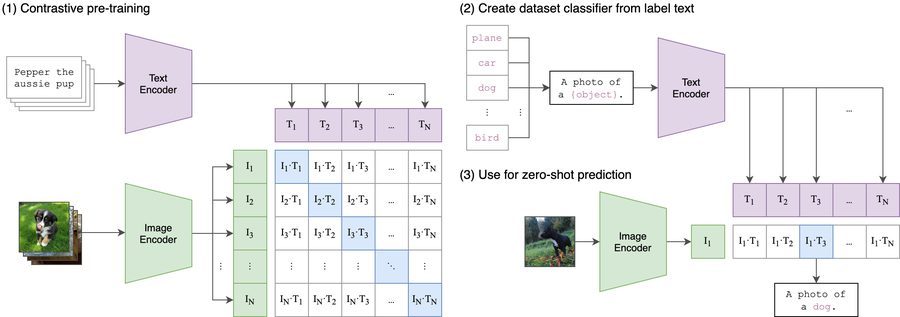

*Figura: OpenAI (2021), repositorio de CLIP, licencia MIT. En el paso 1, los dos codificadores (*encoders*) convierten cada foto (I) y cada texto (T) en vectores, e I·T es la similitud entre ellos; los cuadros azules de la diagonal son los pares que van juntos, y el entrenamiento los acerca. En el paso 2, cada clase se escribe como una frase. En el paso 3, gana la frase más parecida a la foto.*

Para clasificar **no se entrena nada**: se escribe cada clase como una frase, CLIP calcula la **similitud** entre la imagen y cada frase, un puntaje de parecido entre sus vectores, y gana la más parecida. Es la clasificación sin entrenamiento previo, *zero-shot*: cero ejemplos etiquetados. **Las frases son el clasificador:** escribirlas es una decisión de diseño, como el umbral del 4A.

<a id='2-1'></a>
### 2.1 - Primera redacción: el nombre de cada clase

**Desglose del experimento.** La celda siguiente escribe cada clase en español, de la forma más directa: «una foto de una cápsula normal», «… con una burbuja», etc. CLIP compara las 32 cápsulas con las cuatro frases y la celda arma la **matriz de confusión**: cada fila es la clase real y cada columna, la asignada. La diagonal, en verde, son los aciertos.

* Ejecute la siguiente celda para clasificar con la primera redacción. La primera vez, cargar CLIP toma unos segundos.

In [ ]:
# Primera redacción: el nombre de cada clase, en español
FRASES_1 = {
    "normal":  "una foto de una cápsula normal",
    "burbuja": "una foto de una cápsula con una burbuja",
    "deforme": "una foto de una cápsula deforme",
    "mancha":  "una foto de una cápsula con una mancha",
}
clip_1 = rc.clasificar_clip(capsulas, FRASES_1, "redacción 1")

**Análisis.** Una fila con todo en la diagonal es una clase que CLIP reconoce. Una **columna** llena indica que CLIP manda casi todo a esa clase: esa frase queda cerca de cualquier cápsula. Compare la exactitud con el 25 % del azar, y recuerde que con 32 imágenes cada una vale 3 puntos.

La celda siguiente muestra de dónde sale una decisión: la similitud de una cápsula con burbuja con cada frase.

* Ejecute la siguiente celda para ver las similitudes de una imagen.

In [ ]:
# La similitud de una cápsula con cada frase: gana la más alta
rc.mostrar_similitudes(clip_1, "burbuja/burbuja_01.jpg")

**Análisis.** Mire la escala: las similitudes difieren en centésimas. En las fotos de internet una cápsula es una cápsula: los detalles que separan nuestras clases pesan poco frente a lo que todas tienen en común. Por eso la redacción importa tanto.

<a id='2-2'></a>
### 2.2 - Su redacción

CLIP aprendió sobre todo con textos en inglés que describen lo que se ve en la foto. Escriba su redacción **en inglés** y **describiendo cómo se ve** cada clase, no solo cómo se llama.

**Desglose del experimento.** La celda trae como punto de partida la traducción literal de la redacción 1. Ejecútela así una vez; luego reescriba **solo las frases**, no los nombres de las clases que van antes de los dos puntos, y ejecute de nuevo. La comprobación compara con la redacción 1 y señala las clases sin ningún acierto. Haga **dos intentos propios**, unos 5 minutos. Si el mejor no fue el último, vuelva a escribirlo y ejecute: lo que se guarda es la última ejecución.

<details>
<summary><b>Pista</b></summary>

Mire la galería de la sección 1 y describa lo que distingue a cada clase como se lo contaría a alguien que no conoce los nombres de los defectos: la forma (*elongated*, *round*, *oval*), lo que hay adentro (*a small round transparent circle*), el color o el tamaño de una marca (*a tiny black dot*). Una frase por clase, con la misma estructura en las cuatro. Cada frase va entre comillas y termina en coma; si aparece `SyntaxError`, falta una comilla o una coma.

</details>

* Ejecute la celda con las frases de partida; después reescríbalas describiendo cada clase en inglés y ejecute de nuevo, dos veces.

In [ ]:
# ✏️ Su redacción: reescriba en inglés solo las frases (no los nombres antes de los dos puntos), describiendo cómo se ve cada clase
FRASES_2 = {
    "normal":  "a photo of a normal capsule",
    "burbuja": "a photo of a capsule with a bubble",
    "deforme": "a photo of a deformed capsule",
    "mancha":  "a photo of a capsule with a stain",
}
clip_2 = rc.clasificar_clip(capsulas, FRASES_2, "redacción 2")
rc.comprobar_redaccion(clip_2, clip_1, partida=rc.FRASES_TRADUCIDAS)

**La galería de errores** muestra las cápsulas mal clasificadas, con su clase real y la asignada.

* Ejecute la siguiente celda para ver los errores de su redacción.

In [ ]:
# Galería de errores de la redacción 2
rc.mostrar_errores(clip_2)

<a id='2-3'></a>
### 2.3 - Para casa: plantillas y conjuntos de frases

*Si le sobra tiempo en clase, hágala allí; si no, siga a la sección 3.*

Los autores de CLIP midieron dos mejoras en ImageNet, un conjunto de fotos de objetos comunes en mil categorías:
* la **plantilla** «A photo of a {label}.»: sube la exactitud 1,3 puntos frente a la etiqueta sola;
* un **conjunto de frases** por clase, cuyos vectores CLIP promedia: con plantillas y conjuntos de 80 frases, casi 5 puntos.

**Desglose del experimento.** En `PLANTILLAS` escriba de 2 a 4 plantillas, cada una con `{}` donde va la etiqueta, y en `ETIQUETAS` una etiqueta por clase: solo la descripción, sin «a photo of», por ejemplo `"smooth elongated capsule"`. Puede tomarla de su redacción 2. CLIP tolera errores menores de gramática, como «a elongated». La celda arma las frases y muestra la tabla con todas sus redacciones.

* Para casa: agregue plantillas a `PLANTILLAS`, escriba sus etiquetas en `ETIQUETAS` y ejecute la celda.

In [ ]:
# ✏️ Un conjunto de frases por clase: cada plantilla se combina con la etiqueta de cada clase
PLANTILLAS = [
    "a photo of a {}.",
]
ETIQUETAS = {
    "normal":  "normal capsule",
    "burbuja": "capsule with a bubble",
    "deforme": "deformed capsule",
    "mancha":  "capsule with a stain",
}
clip_3 = rc.clasificar_clip(capsulas, rc.frases_con_plantillas(PLANTILLAS, ETIQUETAS), "redacción 3")
rc.mostrar_frases(clip_3)
rc.mostrar_redacciones()

**Análisis.** Una diferencia de una o dos imágenes entre redacciones no es concluyente; el cambio de una clase entera, sí. Si escogió la mejor redacción mirando estas mismas 32 imágenes, su exactitud es optimista: los autores de CLIP reconocen ese problema con sus conjuntos de validación. Y lo que ayuda en ImageNet no tiene por qué ayudar con defectos que casi no aparecen en internet.

**✏️ Su análisis (sección 2).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿Cambiar la redacción cambió el resultado? ¿Qué clases reconoce CLIP y cuáles confunde, y por qué cree que pasa? ¿Escribir las frases se parece a elegir el umbral del 4A?*

*Escriba aquí.*

<a id='3'></a>
## 3 - El LLM multimodal

Un **LLM multimodal**, como Claude, Gemini o GPT, recibe una imagen con una instrucción y responde en texto. La imagen se convierte en **tokens**, como el texto: en Claude, cada cuadrito de 28 × 28 píxeles es un token, así que una imagen cuesta ⌈ancho/28⌉ × ⌈alto/28⌉ tokens, donde ⌈ ⌉ redondea hacia arriba. Una de 1024 × 1024 son 1369; con Haiku 5.5, a US$0,10 por millón de tokens de entrada, mil imágenes así cuestan unos US$0,14. Los tokens de salida, la respuesta, cuestan cinco veces más: US$0,50 por millón (precios del 26-oct-2026).

Frente a CLIP, **la tarea la define la instrucción**, **la respuesta es un texto que hay que verificar** (su documentación advierte que cuenta y ubica objetos de forma aproximada) y **la imagen sale de su computador** hacia el proveedor, que cobra cada una.

**Desglose del experimento.** El LLM recibe las mismas 32 cápsulas y las mismas clases que CLIP, cada una con una definición, y la misma instrucción en todas las llamadas. Si la primera línea de la respuesta no es exactamente una clase, cuenta como **«sin respuesta válida»**, sin adivinar.

* Ejecute la siguiente celda para ver la instrucción.

In [ ]:
# La instrucción que recibe el LLM con cada imagen
rc.mostrar_instruccion()

<a id='3-1'></a>
### 3.1 - Las 32 cápsulas, de 224 píxeles

* Ejecute la siguiente celda para clasificar las cápsulas con el LLM, reducidas a 224 × 224 píxeles. Con la API toma menos de un minuto; con respuestas grabadas, un instante.

In [ ]:
# Clasificar las 32 cápsulas con el LLM, cada una reducida a 224 × 224 píxeles
llm_224 = rc.clasificar_llm(llm, capsulas, lado=224)

**La galería de errores** del LLM trae, debajo de cada imagen, lo que el LLM dijo haber visto.

* Ejecute la siguiente celda para revisar sus errores y sus explicaciones.

In [ ]:
# Galería de errores del LLM, con su explicación
rc.mostrar_errores(llm_224)

**Análisis.** Lea la matriz como la de CLIP. Luego revise cada explicación con la imagen al lado: ¿lo que dice haber visto está en la foto? Una explicación puede describir un defecto que no existe, o negar uno que se ve. Esa revisión es la verificación que el texto exige.

<a id='3-2'></a>
### 3.2 - El tamaño de la imagen

**Desglose del experimento.** Una imagen más grande muestra más detalle, pero cuesta más tokens. Escriba 448, el tamaño original de los recortes, entre los corchetes de `LADOS_LLM`; en casa, agregue 112: `[448, 112]`. Con respuestas grabadas solo hay 112, 224 y 448. La celda compara, por tamaño, los tokens según la fórmula, los medidos, la exactitud y el costo.

* Escriba 448 en `LADOS_LLM` y ejecute la celda.

In [ ]:
# ✏️ Los tamaños, en píxeles, a los que se reduce cada cápsula antes de enviarla al LLM (224 ya está hecho)
LADOS_LLM = []      # por ejemplo [448]; en casa, [448, 112]
rc.probar_tamanos(llm, capsulas, LADOS_LLM)

**Análisis.** La columna «diferencia» debería ser igual en todos los tamaños: son los tokens de la instrucción. Si lo es, la fórmula explica todo el cambio en los tokens de entrada. El costo crece mucho menos que los tokens de la imagen, porque la instrucción y la respuesta, que cuesta cinco veces más, pesan igual en todos los tamaños. En la exactitud, una o dos imágenes de diferencia no prueban nada, porque el LLM puede responder distinto a la misma pregunta (sección 6). Si una clase mejora mucho con más píxeles, el defecto se perdía al reducir la imagen; si falla con todos los tamaños, el problema es lo que el modelo entiende por esa clase.

**✏️ Su análisis (sección 3).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿Qué tamaño elegiría para la estación y por qué, con la exactitud y el costo por 1000 imágenes? ¿Las explicaciones de los errores, en la galería de 224 px, describían lo que se ve en la imagen?*

*Escriba aquí.*

<a id='4'></a>
## 4 - Detectar y contar

**Clasificar** asigna una etiqueta a toda la imagen. **Detectar** encuentra cada objeto: devuelve una **caja**, una **clase** y una **confianza** entre 0 y 1. El **umbral de confianza** decide qué cajas se quedan: otro parámetro de diseño, como el umbral del 4A.

Los detectores como YOLO (Redmon et ál., 2016) se entrenan con **COCO**, fotos de 80 clases de objetos comunes: persona, botella, silla… Solo responden con esas clases. Para piezas propias hay que **ajustarlos** con imágenes etiquetadas con cajas, algo que este laboratorio no hace.

<a id='4-1'></a>
### 4.1 - Un detector entrenado con COCO

Aquí se usa **RT-DETRv2** (Lv et ál., 2024), un detector en tiempo real entrenado con COCO, como YOLO, pero con licencia Apache-2.0 y las mismas librerías que CLIP.

* Ejecute la siguiente celda para ver qué detecta RT-DETRv2 en la foto principal del 4A, con umbral 0,3.

In [ ]:
# Un detector entrenado con las 80 clases de COCO, sobre la foto principal del 4A
coco = rc.detectar_coco("principal", umbral=0.3)

**Análisis.** Mire los nombres de las cajas. COCO no tiene la clase «cápsula», así que el detector responde con el objeto de COCO más parecido, y la confianza no avisa que la clase es imposible. Un detector de clases fijas no conoce sus piezas.

<a id='4-2'></a>
### 4.2 - Un detector que busca lo que usted describe

**OWLv2** (Minderer et ál., 2023, de Google) es un detector de **vocabulario abierto**: como CLIP, compara cada zona de la foto con un texto y devuelve las cajas que se le parecen. No hay que reentrenarlo: hay que describir el objeto.

**Desglose del experimento.** La celda busca `TEXTO_DETECTOR` en la foto principal y deja las cajas con confianza de al menos `UMBRAL_DETECTOR`. Las compara con la referencia: azul, una caja por cápsula; rojo, una caja que encierra dos o más; naranja, una caja de más (sobre la tela o repetida); X magenta, una cápsula perdida. Debajo, una tabla dice cuántas cajas quedan con cada umbral. En el código, los decimales van con punto: `0.25`.

<details>
<summary><b>Pista</b></summary>

Empiece por la tabla: la línea de título dice qué confianza alcanza la mejor caja con ese texto. Si ninguna llega al umbral, describa el objeto como se ve en la foto (en inglés, con su color o su forma) o baje el umbral de a poco. Con un umbral muy bajo aparecen cajas sobre la tela o sobre dos cápsulas a la vez.

</details>

* Cambie el texto y el umbral, y ejecute la celda cada vez, hasta que cada cápsula de la foto principal quede en su caja.

In [ ]:
# ✏️ Qué buscar (en inglés) y desde qué confianza aceptar una caja (entre 0 y 1)
TEXTO_DETECTOR = "a capsule"
UMBRAL_DETECTOR = 0.3
deteccion = rc.detectar_texto("principal", TEXTO_DETECTOR, UMBRAL_DETECTOR)
rc.barrido_umbral("principal", TEXTO_DETECTOR)

<a id='4-3'></a>
### 4.3 - Las tres fotos del 4A

**Desglose del experimento.** Una configuración que funciona en una foto puede fallar en otra. La celda siguiente corre su texto y su umbral en las tres fotos del 4A, y los compara con el pipeline del 4A (con la configuración de la solución del 4A) y con el conteo a mano: 20 cápsulas por foto. La tercera es la foto «límite», con cápsulas pegadas a lo largo, que ninguna configuración del 4A separó.

* Ejecute la siguiente celda para validar el detector en las tres fotos.

In [ ]:
# El detector y el pipeline del 4A en las tres fotos, frente al conteo a mano
rc.validar_detector(TEXTO_DETECTOR, UMBRAL_DETECTOR)

* Ejecute la siguiente celda para ver la foto límite con los dos métodos.

In [ ]:
# La foto límite: las regiones del pipeline del 4A y las cajas del detector
rc.comparar_en_foto("limite")

**Análisis.** Si el detector cuenta bien donde el 4A falla, es porque no necesita fondo entre las cápsulas: aprendió cómo se ve un objeto completo. Pero cuesta segundos por foto frente a milisegundos, y su texto y su umbral se ajustaron con estas mismas fotos. Y una caja no mide: no reemplaza el alargamiento medido sobre la región.

**✏️ Su análisis (sección 4).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿Qué texto y qué umbral funcionaron, y qué pasó con un umbral muy alto o muy bajo? ¿En qué foto el detector superó al pipeline del 4A, y qué costó?*

*Escriba aquí.*

<a id='5'></a>
## 5 - Comparar: ¿cuándo basta el pipeline del 4A?

**Desglose del experimento.** En el 4A, la cápsula deforme se rechazó con una medida diseñada a mano: su **alargamiento** (largo ÷ ancho) se alejaba del típico más que una tolerancia. La celda siguiente aplica esa regla a las 32 cápsulas, con la tolerancia de la solución del 4A, 12 %. Solo responde «rechazar» o «aceptar»: para la burbuja y la mancha habría que diseñar otras medidas.

* Ejecute la siguiente celda para aplicar la regla del 4A.

In [ ]:
# La regla del alargamiento del 4A sobre las 32 cápsulas
regla = rc.regla_alargamiento(capsulas, tolerancia=12)

La tabla siguiente reúne lo que corrió en este notebook: el resultado de cada enfoque, su costo y su tiempo por imagen, y si la imagen sale del computador. El pipeline del 4A y los detectores **cuentan**, la regla del 4A **rechaza** deformes, y CLIP y el LLM **clasifican**.

* Ejecute la siguiente celda para ver la comparación.

In [ ]:
# Los enfoques del laboratorio lado a lado
rc.tabla_comparacion()

El archivo `resultados_4B.csv` usa las columnas de los demás laboratorios de **contrapunto**, que comparan un LLM con una técnica clásica y se analizan juntos en la sesión 8. Tiene una fila por imagen y por foto; `correcto` vale 1 si la respuesta coincide con la referencia.

* Escriba los nombres de la pareja en la celda siguiente y ejecútela para guardar el CSV.

In [ ]:
# ✏️ Nombres de la pareja, para el CSV
PAREJA = "Nombre 1 y Nombre 2"
ruta_csv = rc.exportar_csv(PAREJA)

**Análisis.** Para decidir, combine la tabla con lo que no está en ella:
* **¿Se controla la adquisición?** Entonces el pipeline del 4A cuenta y mide en milisegundos, y cada paso se puede auditar.
* **¿Hay clases que nadie sabe medir?** Los modelos preentrenados permiten empezar sin ejemplos, pero su exactitud se mide con imágenes propias.
* **¿Cuántas imágenes por hora, y pueden salir de la organización?** El LLM cobra cada una y la envía a un tercero.
* **¿Se permite ese uso?** La ficha de CLIP declara fuera de alcance todo uso desplegado sin pruebas en el dominio; YOLO exige licencia empresarial para uso comercial cerrado.

**✏️ Su análisis (sección 5).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. Para la estación de cápsulas, ¿cuándo basta el pipeline del 4A y cuándo usaría CLIP, el LLM o el detector? Justifique con las cifras de su tabla.*

*Escriba aquí.*

<a id='6'></a>
## 6 - Para casa: ¿responde siempre lo mismo el LLM?

La **temperatura** controla cuánto azar usa un LLM al escoger cada palabra. El cliente del curso pide temperatura 0 a OpenAI, a Gemini y al modelo local, para que sus respuestas varíen lo menos posible; la librería de Python de Anthropic ya no ofrece ese parámetro, y Claude usa el suyo. Aun con temperatura 0, un LLM en la nube puede responder distinto a la misma pregunta.

**Desglose del experimento.** La celda envía de nuevo las mismas 32 cápsulas, con la misma instrucción y el mismo tamaño, `REPETICIONES` veces más, y muestra las imágenes que cambiaron de clase. Con respuestas grabadas hay dos repeticiones, de 224 píxeles. Con la API, cada repetición cuesta lo mismo que la sección 3.1.

* Para casa: ejecute la celda con 2 repeticiones.

In [ ]:
# ✏️ Para casa: cuántas veces más se envían las mismas imágenes (de 1 a 5)
REPETICIONES = 2
rc.repetir_llm(llm, capsulas, lado=224, repeticiones=REPETICIONES)

**✏️ Su análisis (sección 6).** *Para casa. ¿Cuántas imágenes cambiaron de clase? ¿Cambió la exactitud de una corrida a otra? ¿Qué implica para comparar dos tamaños de imagen, o dos LLMs, con una sola corrida?*

*Escriba aquí.*

<a id='7'></a>
## 7 - Sus propias imágenes (trabajo independiente TI-2)

El notebook acepta otras imágenes y otras clases sin tocar el código. Para el TI-2:

1. Elija de 2 a 4 clases de un problema de su organización y reúna de 10 a 20 imágenes. **Sin personas, documentos con datos personales ni información confidencial.**
2. Dentro de la carpeta `mis_imagenes/` de este laboratorio, cree **una carpeta por clase** con su nombre, por ejemplo `mis_imagenes/conforme/` y `mis_imagenes/defecto/`, y copie allí las imágenes de cada clase.
3. En la celda siguiente, escriba en `FRASES_PROPIAS` una frase por clase, con el nombre exacto de cada carpeta, y en `FRASES_PROPIAS_2` una segunda redacción, como en la sección 2. Ejecútela: verá las dos matrices de confusión.

* Para casa (TI-2): complete la celda con sus clases y sus frases, y ejecútela.

In [ ]:
# ✏️ Para casa (TI-2): una frase por clase, con el nombre exacto de cada carpeta de mis_imagenes/
FRASES_PROPIAS = {
    "conforme": "a photo of a ...",
    "defecto":  "a photo of a ...",
}
FRASES_PROPIAS_2 = {        # una segunda redacción, para comparar
    "conforme": "a photo of a ...",
    "defecto":  "a photo of a ...",
}
if rc.hay_imagenes_propias("mis_imagenes"):
    mias = rc.cargar_imagenes("mis_imagenes")
    rc.galeria(mias)
    mias_1 = rc.clasificar_clip(mias, FRASES_PROPIAS, "mis imágenes · redacción 1")
    mias_2 = rc.clasificar_clip(mias, FRASES_PROPIAS_2, "mis imágenes · redacción 2")
    rc.mostrar_errores(mias_2)

**El LLM con sus imágenes es opcional.** El TI-2 se puede hacer en el chat de Claude, Gemini o ChatGPT, con la instrucción del enunciado. Si prefiere hacerlo aquí, con la vía API, tenga presente que **cada imagen sale de su computador** hacia los servidores del proveedor. Envíe solo imágenes que su organización le permita compartir. Con la vía local no sale nada; con respuestas grabadas no hay respuestas para sus imágenes.

* Para casa, opcional: si sus imágenes se pueden compartir, cambie `ENVIAR_AL_LLM` a `True` y ejecute la celda.

In [ ]:
# ✏️ Para casa, opcional (TI-2): clasificar sus imágenes con el LLM
ENVIAR_AL_LLM = False          # True solo si sus imágenes no muestran personas ni información confidencial
DEFINICIONES_PROPIAS = None    # o {"conforme": "qué la distingue", "defecto": "qué la distingue"}
LADO_PROPIO = 448
if ENVIAR_AL_LLM and rc.hay_imagenes_propias("mis_imagenes"):
    mias_llm = rc.clasificar_llm(llm, rc.cargar_imagenes("mis_imagenes", mostrar=False), lado=LADO_PROPIO,
                                 definiciones=DEFINICIONES_PROPIAS, experimento="propias")
    rc.mostrar_errores(mias_llm)
else:
    p.nota("No se envió ninguna imagen al LLM. Para hacerlo, cambie ENVIAR_AL_LLM a True.", "info")

<a id='8'></a>
## 8 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_4B.csv`. Uno por pareja, por el canal del curso, al inicio de la semana 3. No entregue su archivo `.env` ni sus imágenes de la sección 7: van en el TI-2.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con sus frases, su texto y su umbral finales, y revíselos sobre esas salidas. Los tiempos cambian un poco en cada ejecución: cítelos redondeados («unos 75 ms»). Con la API, esa ejecución repite las llamadas al LLM, cuyas respuestas pueden cambiar (sección 6): unos US$0,008.

| Criterio | Peso |
| :--- | :--- |
| CLIP: tres redacciones registradas y el análisis de lo que cambió (sección 2) | 25 % |
| LLM: matriz, costo medido frente a la fórmula, efecto del tamaño y revisión de sus explicaciones (sección 3) | 25 % |
| Detectores: texto y umbral justificados, y comparación con el 4A y con el conteo a mano (sección 4) | 20 % |
| Comparación y decisión: cuándo basta el pipeline del 4A, coherente con las salidas (secciones 5 y 6) | 20 % |
| `resultados_4B.csv` completo, con el esquema común | 10 % |

Las imágenes propias de la sección 7 se evalúan con el trabajo independiente TI-2.

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto, redactar las frases o un análisis. El LLM de la sección 3 es parte del ejercicio y no hace falta declararlo.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted resolvió el mismo caso del 4A sin diseñar características: describió las clases con frases para CLIP, le preguntó a un LLM con una instrucción y le dijo a un detector qué buscar. Ninguno se entrenó, y cada uno trajo una decisión de diseño nueva: la redacción, el tamaño de la imagen, el texto y el umbral. Todos se midieron igual: contra las etiquetas reales y el conteo a mano, con su costo y su tiempo.

Es el contrapunto de las sesiones 2 y 3, ahora con imágenes: el pipeline clásico da control y explicación cuando la adquisición es estable; los modelos preentrenados dan flexibilidad, pero su exactitud se mide con las imágenes propias, y la explicación de un LLM se verifica. La **charla de cierre** discute cuándo confiar en lo que ve una máquina, y el **club de lectura** vuelve sobre CLIP: ¿cambiar las frases cambió sus resultados? En el **trabajo independiente TI-2** repetirá la comparación con imágenes de su organización, y en el **proyecto integrador** decidirá si su caso tiene un componente visual.

<a id='referencias'></a>
## Referencias

* Radford, A. et ál. (2021). Learning transferable visual models from natural language supervision. *ICML 2021*, PMLR 139, 8748–8763. [PMLR](https://proceedings.mlr.press/v139/radford21a.html) · OpenAI (2021), [repositorio de CLIP](https://github.com/openai/CLIP), con la [ficha del modelo](https://github.com/openai/CLIP/blob/main/model-card.md).
* Olah, C., Mordvintsev, A. y Schubert, L. (2017). Feature visualization. *Distill*. [distill.pub](https://distill.pub/2017/feature-visualization/)
* Redmon, J., Divvala, S., Girshick, R. y Farhadi, A. (2016). You Only Look Once: unified, real-time object detection. *CVPR 2016*, 779–788. [arXiv](https://arxiv.org/abs/1506.02640)
* Lin, T.-Y. et ál. (2014). Microsoft COCO: common objects in context. *ECCV 2014*. [arXiv](https://arxiv.org/abs/1405.0312)
* Lv, W., Zhao, Y., Chang, Q., Huang, K., Wang, G. y Liu, Y. (2024). RT-DETRv2: improved baseline with bag-of-freebies for real-time detection transformer. [arXiv](https://arxiv.org/abs/2407.17140)
* Minderer, M., Gritsenko, A. y Houlsby, N. (2023). Scaling open-vocabulary object detection. *NeurIPS 2023*. [arXiv](https://arxiv.org/abs/2306.09683)
* Zou, Y., Jeong, J., Pemula, L., Zhang, D. y Dabeer, O. (2022). SPot-the-Difference self-supervised pre-training for anomaly detection and segmentation. *ECCV 2022*. [arXiv](https://arxiv.org/abs/2207.14315) · conjunto VisA, CC BY 4.0: [GitHub](https://github.com/amazon-science/spot-diff)
* Anthropic: [visión](https://platform.claude.com/docs/en/build-with-claude/vision) y [precios](https://platform.claude.com/docs/en/about-claude/pricing) de la API de Claude, consultados el 26-oct-2026.
* Hugging Face Transformers: [CLIP](https://huggingface.co/docs/transformers/model_doc/clip), [OWLv2](https://huggingface.co/docs/transformers/model_doc/owlv2) y [RT-DETRv2](https://huggingface.co/docs/transformers/model_doc/rt_detr_v2).
* Ultralytics (2026). [YOLO26](https://docs.ultralytics.com/models/yolo26/) y sus [licencias](https://www.ultralytics.com/license).